# Step 2 — NLP classique et représentations de texte
**Projet NLP & Computer Vision : détection des maladies des plantes + assistant textuel (RAG)** · Rôle : personne 2 (NLP)

## Objectif
Construire un pipeline de traitement de texte et un **baseline classique** auquel on comparera ensuite le RAG (embeddings + LLM).
Notre corpus est la base de connaissances : **21 documents → 69 passages → 10 maladies** (reformulations en français de fiches d'universités).

Deux tâches, qui correspondent à la partie NLP du système :

| Tâche | Question posée | Méthode classique | Métriques |
|---|---|---|---|
| **A. Classification** | De quelle maladie parle ce passage ? | Naive Bayes, Régression logistique, SVM | Accuracy, précision, rappel, F1 |
| **B. Recherche d'information** | Quels passages répondent à la question de l'utilisateur ? | Similarité cosinus (BoW, TF-IDF, n-grammes) | Hit@k, MRR |

**Protocole d'évaluation (important).** Un passage ne doit jamais être testé avec un autre passage *du même document* dans l'entraînement. On utilise donc la validation **leave-one-document-out** : à chaque tour, un document entier (3 à 4 passages) sert de test et les 20 autres servent à l'entraînement. Les vectoriseurs sont ajustés **uniquement sur l'entraînement** (pas de fuite de données).

Outils (comme dans le TP1) : **NLTK** (tokenisation, stopwords, stemming) et **spaCy** `fr_core_news_sm` (lemmatisation, POS). Rappel du TP1 : `WordNetLemmatizer` ne fonctionne pas en français, donc la lemmatisation passe par spaCy.

In [1]:
import sys
print(sys.executable)
%pip install spacy nltk scikit-learn matplotlib pandas pyyaml
!python -m spacy download fr_core_news_sm

c:\Users\dell\plant-disease-nlp-cv\personne2_nlp\.venv\Scripts\python.exe
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
      --------------------------------------- 0.3/16.3 MB ? eta -:--:--
      --------------------------------------- 0.3/16.3 MB ? eta -:--:--
     - ------------------------------------- 0.5/16.3 MB 618.3 kB/s eta 0:00:26
     - ------------------------------------- 0.5/16.3 MB 618.3 kB/s eta 0:00:26
     - ------------------------------------- 0.5/16.3 MB 618.3 kB/s eta 0:00:26
     - ------------------------------------- 0.5/16.3 MB 618.3 kB/s eta 0:00:26
     - ------------------------------------- 0.5/16.3 MB 618.3 kB/s eta 0:00:26
     - -----------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Installation (une seule fois) :
# !pip install nltk spacy scikit-learn matplotlib pandas pyyaml
# !python -m spacy download fr_core_news_sm
# Optionnel (embeddings pré-entraînés) : !pip install sentence-transformers

import glob, os, re, unicodedata, warnings, yaml
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import nltk, spacy
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
for r in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(r, quiet=True)
nlp = spacy.load("fr_core_news_sm")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Chemins : lancer le notebook depuis le dossier personne2_nlp
DOSSIER_DOCS = "documents"
QUESTIONS_CSV = "data/questions_test.csv"

## 1. Le corpus
Chaque document est découpé par section (`##`) en passages de 250 mots maximum, comme dans `rag.py`.
Le **titre** du document (qui contient le nom de la maladie) n'est **pas** gardé dans le texte : sinon la classification serait triviale (le nom de la maladie serait dans chaque passage).

21 documents | 69 passages | 10 maladies
Longueur des passages : min 10, médiane 69, max 168 mots


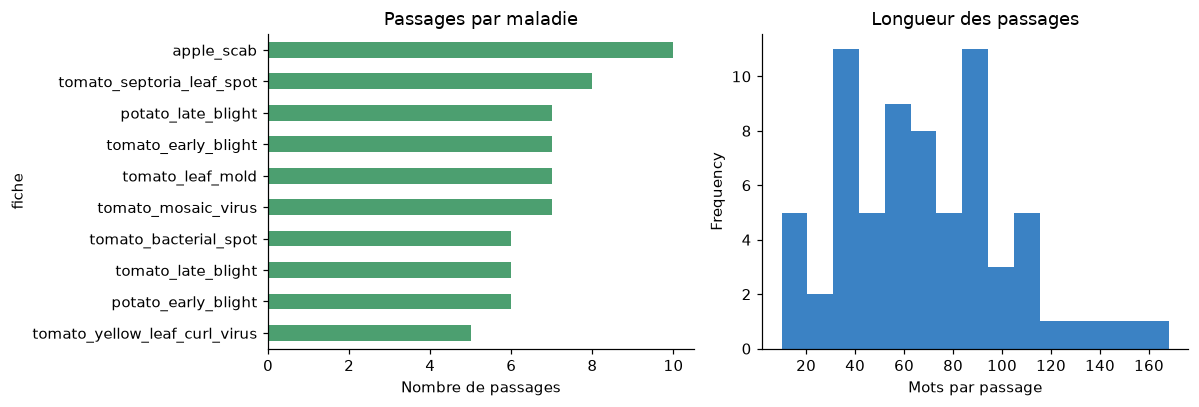

Baseline 'classe majoritaire' : 14.5% | tirage au hasard : 10.0%


In [3]:
def decouper(texte, max_mots=250, chevauchement=50):
    lignes = texte.splitlines()
    if lignes and lignes[0].startswith("# "):
        lignes = lignes[1:]                      # on retire le titre (contient le nom de la maladie)
    sections, courant = [], []
    for ligne in lignes:
        if ligne.startswith("## ") and courant:
            sections.append("\n".join(courant)); courant = []
        courant.append(ligne)
    if courant:
        sections.append("\n".join(courant))
    passages = []
    for s in sections:
        s = s.strip()
        if not s:
            continue
        mots = s.split()
        if len(mots) <= max_mots:
            passages.append(s)
        else:
            pas = max_mots - chevauchement
            passages += [" ".join(mots[i:i + max_mots]) for i in range(0, len(mots), pas)]
    return passages

lignes = []
for f in sorted(glob.glob(f"{DOSSIER_DOCS}/*.md")):
    brut = open(f, encoding="utf-8-sig").read()
    _, meta, texte = brut.split("---", 2)
    m = yaml.safe_load(meta)
    for c in decouper(texte.strip()):
        c = re.sub(r"^#+\s*", "", c, flags=re.M)        # '## Symptômes' -> 'Symptômes'
        lignes.append({"doc": os.path.basename(f), "fiche": m["fiche_kb"],
                       "source": m["source"], "texte": c})
df = pd.DataFrame(lignes)
df["n_mots"] = df.texte.str.split().str.len()

y = df.fiche.values                  # étiquette = maladie
groupes = df.doc.values              # groupe = document (pour leave-one-document-out)
print(f"{df.doc.nunique()} documents | {len(df)} passages | {df.fiche.nunique()} maladies")
print(f"Longueur des passages : min {df.n_mots.min()}, médiane {int(df.n_mots.median())}, max {df.n_mots.max()} mots")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df.fiche.value_counts().sort_values().plot.barh(ax=ax[0], color="#4c9f70")
ax[0].set_title("Passages par maladie"); ax[0].set_xlabel("Nombre de passages")
df.n_mots.plot.hist(bins=15, ax=ax[1], color="#3b82c4")
ax[1].set_title("Longueur des passages"); ax[1].set_xlabel("Mots par passage")
plt.tight_layout(); plt.show()

taux_majoritaire = df.fiche.value_counts(normalize=True).max()
print(f"Baseline 'classe majoritaire' : {taux_majoritaire:.1%} | tirage au hasard : {1/df.fiche.nunique():.1%}")

## 2. Prétraitement du texte (2.1)

Le texte est du **français agronomique** : accents, apostrophes (`l'alternariose`), termes latins (`Phytophthora infestans`), sigles (`TYLCV`), nombres et unités (`49 °C`, `1,3 cm`).

| Opération | Choix | Justification |
|---|---|---|
| Normalisation | minuscules, Unicode NFKC, `’` → `'`, `œ` → `oe` | Évite que `Tache` / `tache` ou `’` / `'` soient des mots différents |
| Nombres et symboles | supprimés dans les variantes « nettoyées » | Les valeurs (`49 °C`) apportent peu pour reconnaître une maladie |
| Ponctuation, apostrophes, traits d'union | remplacés par des espaces | `l'alternariose` → `l` + `alternariose` (`l` est un stopword) |
| Tokenisation | NLTK `word_tokenize(language='french')` | Comme au TP1 ; comparée à celle de spaCy ci-dessous |
| Stopwords | liste française NLTK (+ `is_stop` de spaCy pour la variante lemmes) | Retire `le`, `de`, `et`… qui n'identifient aucune maladie |
| Stemming | `SnowballStemmer('french')` | Rapide mais approximatif (racines non lisibles) |
| Lemmatisation | spaCy `fr_core_news_sm` | Précise : `infectées` → `infecter`, `feuilles` → `feuille` |
| POS | garder NOM, NOM PROPRE, ADJ, VERBE | Les mots de contenu portent le sens (`tache`, `brun`, `jaunir`) |
| Variations orthographiques | `sans_accents()` testée en 5.3 | Un agriculteur tape souvent `bacterienne` sans accent |

In [4]:
STOP_FR = set(stopwords.words("french"))
stemmer = SnowballStemmer("french")
POS_UTILES = {"NOUN", "PROPN", "ADJ", "VERB"}
MODES = ["brut", "nettoye", "sans_stopwords", "stemming", "lemmatisation", "lemmes_utiles"]

def normaliser(t):
    t = unicodedata.normalize("NFKC", t).replace("’", "'").replace("œ", "oe")
    return t.lower()

def nettoyer(t):
    t = re.sub(r"\d+(?:[.,]\d+)?", " ", t)                          # nombres
    t = re.sub(r"[^a-zàâäçéèêëîïôöùûüÿ'\s-]", " ", t)              # ponctuation et symboles
    t = re.sub(r"['-]", " ", t)                                      # apostrophes, traits d'union
    return re.sub(r"\s+", " ", t).strip()

def sans_accents(t):
    return "".join(c for c in unicodedata.normalize("NFD", t) if unicodedata.category(c) != "Mn")

def pretraiter(textes, mode):
    textes = list(textes)
    if mode == "brut":                                    # minuscules seulement
        return [" ".join(normaliser(t).split()) for t in textes]
    if mode in ("nettoye", "sans_stopwords", "stemming"):  # NLTK
        sortie = []
        for t in textes:
            toks = word_tokenize(nettoyer(normaliser(t)), language="french")
            if mode != "nettoye":
                toks = [w for w in toks if w not in STOP_FR]
            if mode == "stemming":
                toks = [stemmer.stem(w) for w in toks]
            sortie.append(" ".join(toks))
        return sortie
    sortie = []                                           # spaCy : lemmatisation (+ POS)
    for doc in nlp.pipe([normaliser(t) for t in textes], batch_size=32):
        toks = [w for w in doc if w.is_alpha and not w.is_stop and w.lemma_.lower() not in STOP_FR]
        if mode == "lemmes_utiles":
            toks = [w for w in toks if w.pos_ in POS_UTILES]
        sortie.append(" ".join(w.lemma_.lower() for w in toks))
    return sortie

In [5]:
exemple = "Les taches s'agrandissent, se rejoignent et peuvent tuer des feuilles entières (jusqu'à 1,3 cm de diamètre)."
print("TOKENISATION")
print("  NLTK :", word_tokenize(exemple, language="french"))
print("  spaCy:", [t.text for t in nlp(exemple)])

print("\nSTEMMING vs LEMMATISATION (mot par mot)")
tab = [(t.text, stemmer.stem(t.text), t.lemma_, t.pos_) for t in nlp(exemple) if t.is_alpha]
print(pd.DataFrame(tab, columns=["mot", "racine (stemming)", "lemme (spaCy)", "POS"]).to_string(index=False))

print("\nRÉSULTAT DE CHAQUE PIPELINE SUR LA PHRASE")
for mode in MODES:
    print(f"  {mode:16s}→ {pretraiter([exemple], mode)[0]}")

TOKENISATION
  NLTK : ['Les', 'taches', "s'agrandissent", ',', 'se', 'rejoignent', 'et', 'peuvent', 'tuer', 'des', 'feuilles', 'entières', '(', "jusqu'à", '1,3', 'cm', 'de', 'diamètre', ')', '.']
  spaCy: ['Les', 'taches', "s'", 'agrandissent', ',', 'se', 'rejoignent', 'et', 'peuvent', 'tuer', 'des', 'feuilles', 'entières', '(', "jusqu'", 'à', '1,3', 'cm', 'de', 'diamètre', ')', '.']

STEMMING vs LEMMATISATION (mot par mot)
         mot racine (stemming) lemme (spaCy)   POS
         Les                le            le   DET
      taches              tach         tache  NOUN
agrandissent            agrand      agrandir   ADV
          se                se            se  PRON
  rejoignent        rejoignent     rejoindre  VERB
          et                et            et CCONJ
     peuvent           peuvent       pouvoir  VERB
        tuer                tu          tuer  VERB
         des                de            un   DET
    feuilles            feuill       feuille   ADJ
    entière

### Effet du prétraitement
On compare les 6 pipelines sur trois critères : taille du vocabulaire, classification (TF-IDF + SVM linéaire, leave-one-document-out) et recherche (TF-IDF + cosinus sur les questions de test).

40 questions avec réponse | 5 questions hors base


,vocabulaire,mots/passage,accuracy (classif.),F1 macro (classif.),Hit@1 (recherche),MRR (recherche)
pipeline,,,,,,
brut,1093,69.0,0.319,0.292,0.850,0.915
nettoye,1073,70.2,0.319,0.292,0.850,0.915
sans_stopwords,1031,39.8,0.333,0.314,0.900,0.946
stemming,826,39.8,0.348,0.331,0.900,0.931
lemmatisation,785,33.5,0.348,0.322,0.875,0.929
lemmes_utiles,746,32.0,0.377,0.349,0.900,0.942


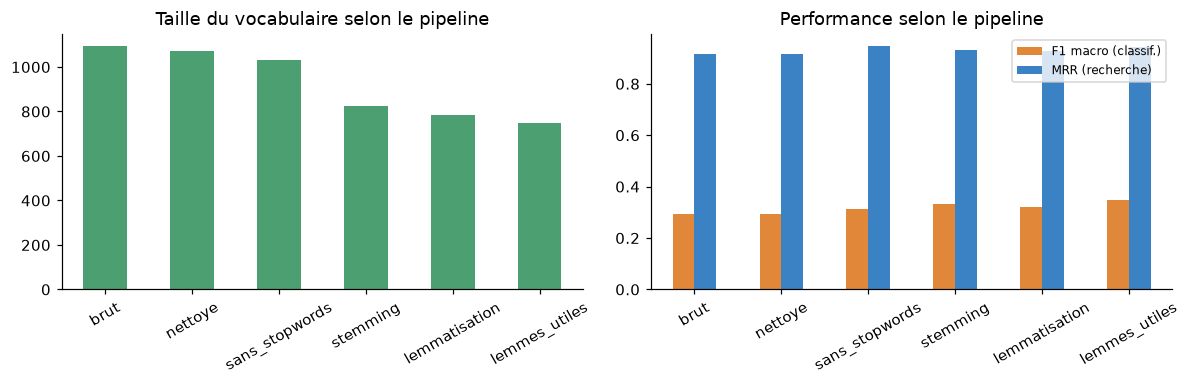

In [6]:
logo = LeaveOneGroupOut()

def evaluer(X, vec, clf):
    pipe = make_pipeline(vec, clf)       # le vectoriseur est ré-ajusté à chaque tour, sur l'entraînement seul
    pred = cross_val_predict(pipe, np.array(X), y, groups=groupes, cv=logo)
    return pred, accuracy_score(y, pred), f1_score(y, pred, average="macro")

# --- questions de test (45 questions : 40 avec réponse dans la base, 5 hors base) ---
Q = pd.read_csv(QUESTIONS_CSV)
Qa = Q[Q.fiche_kb != "AUCUNE"].reset_index(drop=True)      # questions avec réponse
Qh = Q[Q.fiche_kb == "AUCUNE"].reset_index(drop=True)      # questions hors base
print(f"{len(Qa)} questions avec réponse | {len(Qh)} questions hors base")

def similarites(vec, corpus, requetes):
    M = vec.fit_transform(corpus)
    return cosine_similarity(vec.transform(requetes), M)

def metriques_retrieval(S, vraies):
    hits = {1: [], 3: [], 5: []}; rr = []; rangs = []
    for s, v in zip(S, vraies):
        ordre = np.argsort(-s)
        pos = int(np.where(df.fiche.values[ordre] == v)[0][0])   # rang du 1er passage de la bonne maladie
        rangs.append(pos + 1); rr.append(1 / (pos + 1))
        for k in hits:
            hits[k].append(pos < k)
    res = {f"Hit@{k}": float(np.mean(v)) for k, v in hits.items()}
    res["MRR"] = float(np.mean(rr))
    return res, rangs

lignes = []
for mode in MODES:
    corpus = pretraiter(df.texte, mode)
    requetes = pretraiter(Qa.question, mode)
    _, acc, f1 = evaluer(corpus, TfidfVectorizer(sublinear_tf=True), LinearSVC())
    r, _ = metriques_retrieval(similarites(TfidfVectorizer(sublinear_tf=True), corpus, requetes), Qa.fiche_kb)
    lignes.append({"pipeline": mode,
                   "vocabulaire": len(CountVectorizer().fit(corpus).vocabulary_),
                   "mots/passage": round(np.mean([len(c.split()) for c in corpus]), 1),
                   "accuracy (classif.)": acc, "F1 macro (classif.)": f1,
                   "Hit@1 (recherche)": r["Hit@1"], "MRR (recherche)": r["MRR"]})
effet = pd.DataFrame(lignes).set_index("pipeline")
display(effet.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
effet["vocabulaire"].plot.bar(ax=ax[0], color="#4c9f70", rot=30)
ax[0].set_title("Taille du vocabulaire selon le pipeline"); ax[0].set_xlabel("")
effet[["F1 macro (classif.)", "MRR (recherche)"]].plot.bar(ax=ax[1], rot=30, color=["#e0873a", "#3b82c4"])
ax[1].set_title("Performance selon le pipeline"); ax[1].set_xlabel(""); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Choix du pipeline
On retient **`lemmes_utiles`** (normalisation, lemmatisation spaCy, stopwords retirés, seulement noms, adjectifs et verbes) pour toutes les représentations à base de mots :
- il réduit fortement le vocabulaire (moins de dispersion : `feuille` / `feuilles`, `infecter` / `infectées` deviennent un seul mot) ;
- il donne la meilleure F1 macro en classification et une recherche proche du meilleur résultat ;
- les différences entre pipelines sont **petites** (une ou deux questions, un ou deux passages) : on ne conclut pas qu'il est « le meilleur », seulement qu'il est le plus raisonnable.

Pour les **n-grammes de caractères** (3.), on garde le texte `nettoye` : pas de lemmatisation, car les caractères gèrent déjà les variations de forme.

## 3. Représentations du texte (2.2)

| Représentation | Ce qu'elle capture | Ce qu'elle ne capture pas |
|---|---|---|
| **Bag of Words** | Quels mots apparaissent et combien de fois | L'ordre, le contexte, le sens ; les mots fréquents dominent |
| **TF-IDF** | Les mots *caractéristiques* d'un passage (fréquents ici, rares ailleurs) | Toujours ni ordre ni sens ; `tache brune` ≠ `brunissement` |
| **N-grammes de mots (1-2)** | Un peu d'ordre local (`taches brunes`, `centre gris`) | Le sens ; vocabulaire beaucoup plus grand pour peu de données |
| **N-grammes de caractères (3-5)** | Racines, fautes d'orthographe, accents oubliés | Le sens ; les mots proches mais écrits différemment (`mildiou` / `late blight`) |
| **Embeddings pré-entraînés** (MiniLM multilingue) | Le **sens** : `jaunissement` proche de `feuilles jaunes`, et même entre langues | Peu transparent ; peut confondre des maladies très proches |

In [7]:
MODE_CHOISI = "lemmes_utiles"
TXT = {"lemmes": pretraiter(df.texte, MODE_CHOISI), "char": pretraiter(df.texte, "nettoye")}
TXT_Q = {"lemmes": pretraiter(Qa.question, MODE_CHOISI), "char": pretraiter(Qa.question, "nettoye")}
TXT_H = {"lemmes": pretraiter(Qh.question, MODE_CHOISI), "char": pretraiter(Qh.question, "nettoye")}

def fabriques():
    return {
     "BoW":                        (lambda: CountVectorizer(), "lemmes"),
     "TF-IDF (mots)":              (lambda: TfidfVectorizer(sublinear_tf=True), "lemmes"),
     "TF-IDF (mots 1-2 grammes)":  (lambda: TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2)), "lemmes"),
     "TF-IDF (caractères 3-5)":    (lambda: TfidfVectorizer(sublinear_tf=True, analyzer="char_wb", ngram_range=(3, 5)), "char"),
    }
REPS = fabriques()

# --- embeddings pré-entraînés (optionnel : nécessite sentence-transformers et un accès au modèle) ---
EMB_OK = False
try:
    from sentence_transformers import SentenceTransformer
    st = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
    EMB_P = st.encode(df.texte.tolist(), normalize_embeddings=True)
    EMB_Q = st.encode(Qa.question.tolist(), normalize_embeddings=True)
    EMB_H = st.encode(Qh.question.tolist(), normalize_embeddings=True)
    EMB_OK = True
    print("Embeddings MiniLM chargés :", EMB_P.shape)
except Exception as e:
    print("Embeddings indisponibles ici (", type(e).__name__, ") : la ligne 'Embeddings' sera ajoutée "
          "quand tu relanceras le notebook sur ta machine (après pip install sentence-transformers).")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Embeddings MiniLM chargés : (69, 384)


,6 mots les plus caractéristiques
apple_scab,"tavelure, pommier, champignon, variété, orneme..."
potato_early_blight,"alternariose, tubercule, alternaria, cycle, so..."
potato_late_blight,"mildiou, tubercule, infecter, vert, organisme,..."
tomato_bacterial_spot,"bactérien, fruit, bactérie, tache, lésion, espèce"
tomato_early_blight,"jardin, alternaria, feuille, champignon, malad..."
tomato_late_blight,"mildiou, tomate, terre, maladie, pomme, lésion"
tomato_leaf_mold,"ouvrier, nouveau, cladosporiose, outil, tunnel..."
tomato_mosaic_virus,"virus, tomv, tomate, semence, variété, mosaïque"
tomato_septoria_leaf_spot,"septoriose, septoria, champignon, causer, mala..."
tomato_yellow_leaf_curl_virus,"symptôme, plant, tylcv, virus, identifier, mon..."


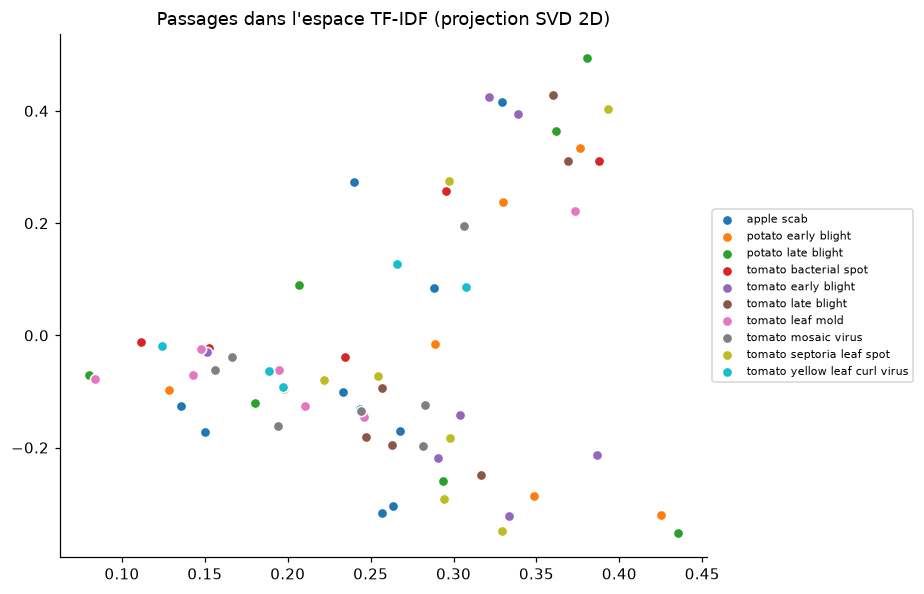

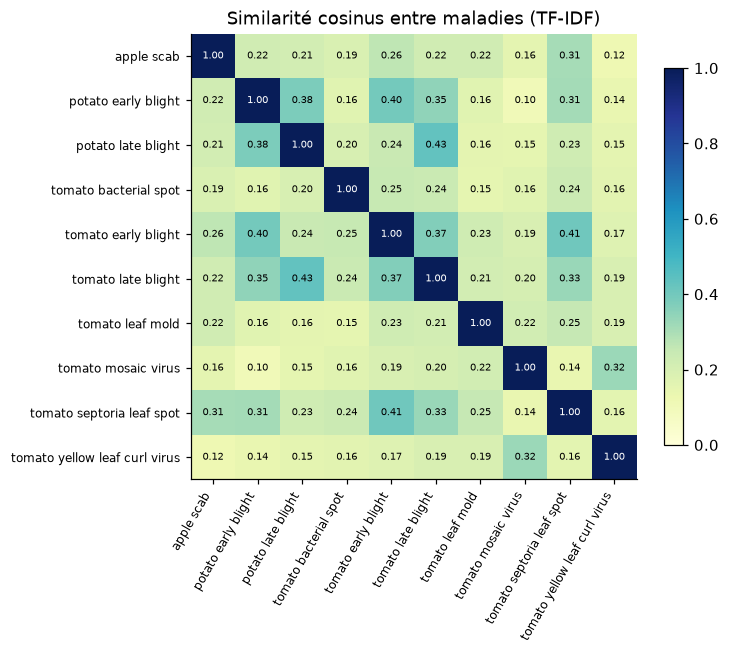

In [8]:
# (a) Mots les plus caractéristiques de chaque maladie (TF-IDF moyen)
vec = TfidfVectorizer(sublinear_tf=True)
X = vec.fit_transform(TXT["lemmes"]); mots = np.array(vec.get_feature_names_out())
tops = {}
for mal in sorted(df.fiche.unique()):
    moy = np.asarray(X[(df.fiche == mal).values].mean(axis=0)).ravel()
    tops[mal] = ", ".join(mots[np.argsort(-moy)[:6]])
display(pd.Series(tops, name="6 mots les plus caractéristiques").to_frame())

# (b) Projection 2D des passages (SVD sur le TF-IDF)
Z = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
couleurs = plt.cm.tab10(np.arange(10))
for c, mal in zip(couleurs, sorted(df.fiche.unique())):
    idx = (df.fiche == mal).values
    ax.scatter(Z[idx, 0], Z[idx, 1], color=c, label=mal.replace("_", " "), s=45, edgecolor="white")
ax.set_title("Passages dans l'espace TF-IDF (projection SVD 2D)")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5)); plt.tight_layout(); plt.show()

# (c) Similarité entre maladies (centroïdes TF-IDF) : quelles maladies se ressemblent ?
mal_list = sorted(df.fiche.unique())
cent = np.vstack([np.asarray(X[(df.fiche == m).values].mean(axis=0)).ravel() for m in mal_list])
sim = cosine_similarity(cent)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sim, cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels([m.replace("_", " ") for m in mal_list], rotation=60, ha="right", fontsize=8)
ax.set_yticklabels([m.replace("_", " ") for m in mal_list], fontsize=8)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="black" if sim[i, j] < .6 else "white")
ax.set_title("Similarité cosinus entre maladies (TF-IDF)"); plt.colorbar(im, shrink=.8); plt.tight_layout(); plt.show()

## 4. Méthodes classiques (2.3)

### 4.A Classification d'un passage en maladie
Représentations × modèles, évalués en **leave-one-document-out** (21 tours, 69 prédictions).

In [9]:
MODELES = {"Naive Bayes": MultinomialNB(alpha=0.1),
           "Rég. logistique": LogisticRegression(max_iter=3000, C=10),
           "SVM linéaire": LinearSVC()}

resultats, preds = [], {}
for rn, (fab, src) in REPS.items():
    for mn, clf in MODELES.items():
        p, acc, f1 = evaluer(TXT[src], fab(), clf)
        preds[(rn, mn)] = p
        resultats.append({"représentation": rn, "modèle": mn, "accuracy": acc, "F1 macro": f1})
if EMB_OK:
    for mn in ["Rég. logistique", "SVM linéaire"]:
        p = cross_val_predict(MODELES[mn], EMB_P, y, groups=groupes, cv=logo)
        preds[("Embeddings MiniLM", mn)] = p
        resultats.append({"représentation": "Embeddings MiniLM", "modèle": mn,
                          "accuracy": accuracy_score(y, p), "F1 macro": f1_score(y, p, average="macro")})
res = pd.DataFrame(resultats)

print(f"Repères : hasard = {1/df.fiche.nunique():.1%} | classe majoritaire = {taux_majoritaire:.1%}\n")
print("ACCURACY"); display(res.pivot(index="représentation", columns="modèle", values="accuracy").round(3))
print("F1 MACRO"); display(res.pivot(index="représentation", columns="modèle", values="F1 macro").round(3))

Repères : hasard = 10.0% | classe majoritaire = 14.5%

ACCURACY


modèle,Naive Bayes,Rég. logistique,SVM linéaire
représentation,,,
BoW,0.464,0.275,0.348
Embeddings MiniLM,NaN,0.217,0.290
TF-IDF (caractères 3-5),0.203,0.275,0.362
TF-IDF (mots 1-2 grammes),0.246,0.246,0.348
TF-IDF (mots),0.304,0.275,0.377


F1 MACRO


modèle,Naive Bayes,Rég. logistique,SVM linéaire
représentation,,,
BoW,0.454,0.261,0.336
Embeddings MiniLM,NaN,0.190,0.223
TF-IDF (caractères 3-5),0.141,0.231,0.315
TF-IDF (mots 1-2 grammes),0.197,0.181,0.303
TF-IDF (mots),0.285,0.224,0.349


Meilleure configuration : BoW + Naive Bayes  (accuracy 0.464, F1 macro 0.454)
IC 95 % accuracy : [0.35 ; 0.58] | F1 macro : [0.33 ; 0.55]


,precision,recall,f1-score,support
apple_scab,0.75,0.60,0.67,10.0
potato_early_blight,0.00,0.00,0.00,6.0
potato_late_blight,0.50,0.71,0.59,7.0
tomato_bacterial_spot,1.00,0.33,0.50,6.0
tomato_early_blight,0.17,0.29,0.21,7.0
tomato_late_blight,0.20,0.17,0.18,6.0
tomato_leaf_mold,0.83,0.71,0.77,7.0
tomato_mosaic_virus,0.75,0.86,0.80,7.0
tomato_septoria_leaf_spot,0.20,0.25,0.22,8.0
tomato_yellow_leaf_curl_virus,0.60,0.60,0.60,5.0


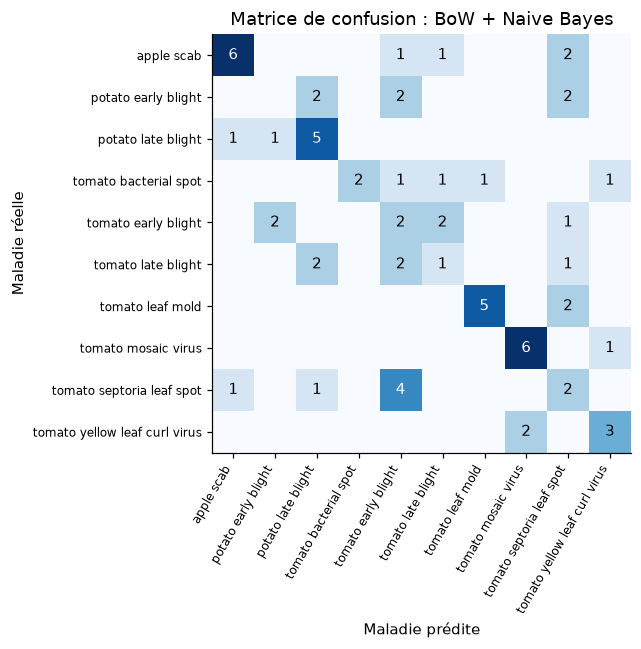

37 passages mal classés sur 69. Exemples :


,doc,fiche,prediction,extrait
0,apple_scab_01.md,apple_scab,tomato_septoria_leaf_spot,Symptômes\n\nDes lésions de tavelure apparaiss...
1,apple_scab_02.md,apple_scab,tomato_early_blight,Survie du champignon\n\nLe champignon passe l'...
2,apple_scab_03.md,apple_scab,tomato_late_blight,"Symptômes\n\nÀ la fin du printemps, des taches..."
3,apple_scab_03.md,apple_scab,tomato_septoria_leaf_spot,Propagation\n\nDes spores sont produites sur l...
4,potato_early_blight_01.md,potato_early_blight,tomato_early_blight,Cause et hôtes\n\nL'alternariose est causée pa...
5,potato_early_blight_01.md,potato_early_blight,potato_late_blight,Symptômes\n\nLes premiers symptômes sont de pe...
6,potato_early_blight_01.md,potato_early_blight,tomato_septoria_leaf_spot,Propagation\n\nLes spores (conidies) qui cause...
7,potato_early_blight_02.md,potato_early_blight,potato_late_blight,Symptômes\n\nL'alternariose touche surtout les...
8,potato_early_blight_02.md,potato_early_blight,tomato_early_blight,Cycle de la maladie\n\nLe champignon de l'alte...
9,potato_early_blight_02.md,potato_early_blight,tomato_septoria_leaf_spot,Gestion\n\nOn peut réduire l'alternariose en m...


In [10]:
meilleur = res.sort_values("F1 macro", ascending=False).iloc[0]
cle = (meilleur["représentation"], meilleur["modèle"])
pred = preds[cle]
print(f"Meilleure configuration : {cle[0]} + {cle[1]}  (accuracy {meilleur['accuracy']:.3f}, F1 macro {meilleur['F1 macro']:.3f})")

# Intervalle de confiance (bootstrap sur les 69 prédictions) : la taille du corpus rend les scores instables
rng = np.random.default_rng(42); accs, f1s = [], []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    accs.append(accuracy_score(y[i], pred[i])); f1s.append(f1_score(y[i], pred[i], average="macro"))
print(f"IC 95 % accuracy : [{np.percentile(accs, 2.5):.2f} ; {np.percentile(accs, 97.5):.2f}] | "
      f"F1 macro : [{np.percentile(f1s, 2.5):.2f} ; {np.percentile(f1s, 97.5):.2f}]")

rapport = pd.DataFrame(classification_report(y, pred, output_dict=True, zero_division=0)).T.round(2)
display(rapport.loc[sorted(df.fiche.unique()) + ["macro avg"], ["precision", "recall", "f1-score", "support"]])

labs = sorted(df.fiche.unique()); cm = confusion_matrix(y, pred, labels=labs)
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels([l.replace("_", " ") for l in labs], rotation=60, ha="right", fontsize=8)
ax.set_yticklabels([l.replace("_", " ") for l in labs], fontsize=8)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Maladie prédite"); ax.set_ylabel("Maladie réelle")
ax.set_title(f"Matrice de confusion : {cle[0]} + {cle[1]}"); plt.tight_layout(); plt.show()

erreurs = df.assign(prediction=pred)[pred != y]
erreurs = erreurs.assign(extrait=erreurs.texte.str.slice(0, 90) + "…")
print(f"{len(erreurs)} passages mal classés sur {len(df)}. Exemples :")
display(erreurs[["doc", "fiche", "prediction", "extrait"]].head(12).reset_index(drop=True))

### 4.B Recherche d'information (similarité vectorielle)
Chaque question est comparée à tous les passages par **similarité cosinus**. Un passage est *pertinent* s'il appartient à la bonne maladie.
- **Hit@k** : la bonne maladie apparaît parmi les k premiers passages.
- **MRR** : moyenne de 1 / (rang du premier bon passage).

,Hit@1,Hit@3,Hit@5,MRR
représentation,,,,
BoW,0.775,0.975,1.00,0.873
TF-IDF (mots),0.900,1.000,1.00,0.942
TF-IDF (mots 1-2 grammes),0.825,1.000,1.00,0.900
TF-IDF (caractères 3-5),0.900,0.975,1.00,0.944
Embeddings MiniLM,0.550,0.725,0.75,0.662


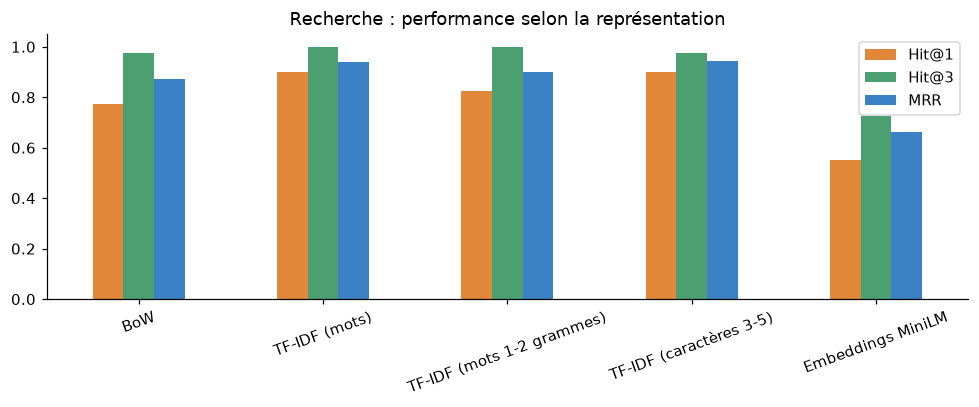

In [11]:
lignes, rangs_par_rep, S_par_rep = [], {}, {}
for rn, (fab, src) in REPS.items():
    S = similarites(fab(), TXT[src], TXT_Q[src]); S_par_rep[rn] = S
    r, rangs = metriques_retrieval(S, Qa.fiche_kb); rangs_par_rep[rn] = rangs
    lignes.append({"représentation": rn, **r})
if EMB_OK:
    S = cosine_similarity(EMB_Q, EMB_P); S_par_rep["Embeddings MiniLM"] = S
    r, rangs = metriques_retrieval(S, Qa.fiche_kb); rangs_par_rep["Embeddings MiniLM"] = rangs
    lignes.append({"représentation": "Embeddings MiniLM", **r})
ret = pd.DataFrame(lignes).set_index("représentation")
display(ret.round(3))

ax = ret[["Hit@1", "Hit@3", "MRR"]].plot.bar(figsize=(9, 3.8), rot=20, color=["#e0873a", "#4c9f70", "#3b82c4"])
ax.set_title("Recherche : performance selon la représentation"); ax.set_xlabel(""); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

In [12]:
meilleure_rep = ret["MRR"].idxmax(); rangs = np.array(rangs_par_rep[meilleure_rep])
print(f"Meilleure représentation (MRR) : {meilleure_rep}")

# MRR par type de question
d = Qa.assign(rr=1 / rangs, rang=rangs)
display(d.groupby("type").agg(questions=("rr", "size"), MRR=("rr", "mean")).round(3))

# Questions difficiles (la bonne maladie n'est pas dans le top 1)
difficiles = d[d.rang > 1][["question", "fiche_kb", "rang"]]
print(f"{len(difficiles)} question(s) où la bonne maladie n'est pas en 1re position :")
display(difficiles.assign(question=difficiles.question.str.slice(0, 95) + "…").reset_index(drop=True))

Meilleure représentation (MRR) : TF-IDF (caractères 3-5)


,questions,MRR
type,,
cause,9,0.944
prevention,9,0.917
propagation,1,1.000
symptomes,15,0.933
traitement,6,1.000


4 question(s) où la bonne maladie n'est pas en 1re position :


,question,fiche_kb,rang
0,Mes tomates sous serre ont des taches vert cla...,tomato_leaf_mold,2
1,Pourquoi une variété résistante ne suffit-elle...,tomato_leaf_mold,4
2,Comment distinguer la septoriose de l'alternar...,tomato_septoria_leaf_spot,2
3,Quel insecte transmet ce virus aux tomates ?…,tomato_yellow_leaf_curl_virus,2


In [14]:
print("max_seq_length :", st.max_seq_length)
n_tok = [len(st.tokenizer.encode(t)) for t in df.texte]
print("passages au-delà de la limite :", sum(n > st.max_seq_length for n in n_tok), "/", len(n_tok),
      "| médiane :", int(np.median(n_tok)), "tokens")

st.max_seq_length = 256                      # on laisse lire des passages plus longs
EMB_P2 = st.encode(df.texte.tolist(), normalize_embeddings=True)
r, _ = metriques_retrieval(cosine_similarity(EMB_Q, EMB_P2), Qa.fiche_kb)
print("MiniLM avec 256 tokens :", {k: round(v, 3) for k, v in r.items()})

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (181 > 128). Running this sequence through the model will result in indexing errors


max_seq_length : 128
passages au-delà de la limite : 28 / 69 | médiane : 107 tokens
MiniLM avec 256 tokens : {'Hit@1': 0.55, 'Hit@3': 0.75, 'Hit@5': 0.825, 'MRR': 0.668}


### 4.C Deux tests de robustesse
1. **Questions hors base** : un système doit pouvoir répondre « je ne sais pas ». La similarité maximale permet-elle de détecter ces questions ?
2. **Accents oubliés** : la recherche tient-elle si l'utilisateur écrit `bacterienne` au lieu de `bactérienne` ?

[TF-IDF (caractères 3-5)] similarité max — questions AVEC réponse : moyenne 0.40 (min 0.24) | questions HORS BASE : moyenne 0.27 (max 0.34)


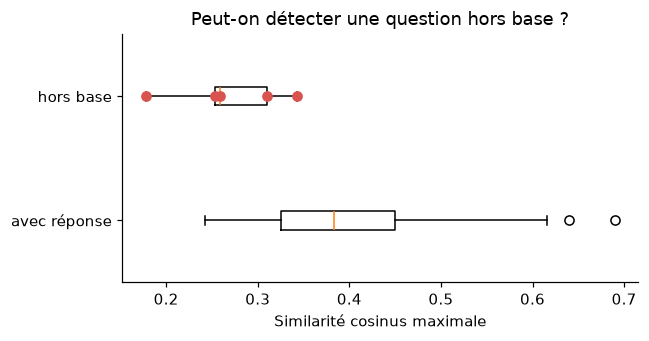


MRR avec et sans accents (strip_accents='unicode' appliqué des deux côtés) :


,questions avec accents,questions sans accents
TF-IDF (mots),0.942,0.925
TF-IDF (caractères 3-5),0.921,0.921


In [13]:
fab, src = REPS[meilleure_rep] if meilleure_rep in REPS else REPS["TF-IDF (mots)"]
nom = meilleure_rep if meilleure_rep in REPS else "TF-IDF (mots)"

# 1) Questions hors base : similarité maximale avec les passages
vec_r = fab(); M = vec_r.fit_transform(TXT[src])
top_ok = cosine_similarity(vec_r.transform(TXT_Q[src]), M).max(axis=1)
top_hb = cosine_similarity(vec_r.transform(TXT_H[src]), M).max(axis=1)
print(f"[{nom}] similarité max — questions AVEC réponse : moyenne {top_ok.mean():.2f} (min {top_ok.min():.2f}) | "
      f"questions HORS BASE : moyenne {top_hb.mean():.2f} (max {top_hb.max():.2f})")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.boxplot([top_ok, top_hb], vert=False); ax.set_yticklabels(["avec réponse", "hors base"])
ax.scatter(top_hb, np.full(len(top_hb), 2), color="#d9534f", zorder=3)
ax.set_xlabel("Similarité cosinus maximale"); ax.set_title("Peut-on détecter une question hors base ?")
plt.tight_layout(); plt.show()

# 2) Accents oubliés
def mrr_sans_accents(nom_rep, accents_requete):
    fab_, src_ = REPS[nom_rep]
    corpus = TXT[src_]
    if src_ == "char":
        qs = [sans_accents(q) for q in Qa.question] if not accents_requete else list(Qa.question)
        qs = pretraiter(qs, "nettoye")
        vec_ = TfidfVectorizer(sublinear_tf=True, analyzer="char_wb", ngram_range=(3, 5), strip_accents="unicode")
    else:
        qs = [sans_accents(q) for q in Qa.question] if not accents_requete else list(Qa.question)
        qs = pretraiter(qs, MODE_CHOISI)
        vec_ = TfidfVectorizer(sublinear_tf=True, strip_accents="unicode")
    r, _ = metriques_retrieval(similarites(vec_, corpus, qs), Qa.fiche_kb)
    return r["MRR"]
rob = pd.DataFrame({"questions avec accents": [mrr_sans_accents(n, True) for n in ["TF-IDF (mots)", "TF-IDF (caractères 3-5)"]],
                    "questions sans accents": [mrr_sans_accents(n, False) for n in ["TF-IDF (mots)", "TF-IDF (caractères 3-5)"]]},
                   index=["TF-IDF (mots)", "TF-IDF (caractères 3-5)"])
print("\nMRR avec et sans accents (strip_accents='unicode' appliqué des deux côtés) :")
display(rob.round(3))

## 5. Évaluation du baseline et conclusion (2.4)

### 5.1 Protocole d'évaluation
- **Données** : 21 documents, 69 passages, 10 maladies ; 45 questions de test (40 avec réponse dans la base, 5 hors base).
- **Classification** : leave-one-document-out (21 tours), vectoriseurs ajustés sur l'entraînement seul. Métriques : accuracy, précision, rappel, F1 macro, avec intervalle de confiance bootstrap. Repères : hasard = 10 %, classe majoritaire = 14,5 %.
- **Recherche** : similarité cosinus entre la question et les 69 passages ; un passage est pertinent s'il appartient à la bonne maladie. Métriques : Hit@1, Hit@3, Hit@5, MRR.

### 5.2 Résultats du baseline (valeurs de notre exécution)
| Tâche | Meilleur baseline classique | Résultat |
|---|---|---|
| Classification d'un passage | BoW + Naive Bayes | accuracy 0,46 · F1 macro 0,45 (IC 95 % de l'accuracy : 0,35 à 0,58) |
| Recherche d'information | TF-IDF (mots ou caractères 3-5) | Hit@1 0,90 · Hit@3 ≈ 1,0 · MRR ≈ 0,94 |

1. **La recherche fonctionne bien** : le TF-IDF (MRR 0,94) dépasse nettement le BoW simple (0,87), ce qui montre l'intérêt de pondérer les mots rares. Les n-grammes de mots (1-2) n'aident pas (0,90) : le corpus est trop petit.
2. **La classification est faible mais bien au-dessus du hasard** (46 % contre 10 %). La projection 2D (section 3) montre des passages de maladies différentes mélangés, sans groupes nets. Les trois modèles (Naive Bayes, régression logistique, SVM) donnent des scores proches, avec un intervalle de confiance très large (± 12 points) : on ne peut pas affirmer qu'un modèle est meilleur qu'un autre.
3. **Le prétraitement réduit le vocabulaire de 30 %** (1 073 → 746 mots) mais n'améliore les scores que modestement (environ +6 points de F1 en classification, +3 points de MRR en recherche par rapport au texte simplement nettoyé), dans la marge d'erreur.
4. **Questions hors base** : la similarité maximale est plus faible en moyenne (0,27) que pour les questions avec réponse (0,40), mais les deux groupes se chevauchent : un seuil de similarité seul ne suffit pas à répondre « je ne sais pas ».
5. **Accents oubliés** : la perte est faible (moins de 2 points de MRR) avec `strip_accents`, et nulle avec les n-grammes de caractères.

### 5.3 Limites du baseline
- **Pas de sémantique** : le TF-IDF ne relie pas des mots différents qui disent la même chose (`jaunissement` / `feuilles jaunes`), ni les langues (`mildiou` / `late blight`). Les questions en français familier ou en darija seront mal servies.
- **Pas de contexte** : les sections génériques (« Gestion », « Propagation ») se ressemblent d'une maladie à l'autre. Les maladies les plus proches dans l'espace TF-IDF sont le mildiou de la pomme de terre et de la tomate (similarité 0,43), l'alternariose et la septoriose de la tomate (0,41), l'alternariose de la pomme de terre et de la tomate (0,40, même champignon *Alternaria*). Avec la meilleure configuration, la F1 de `potato_early_blight` est de 0.
- **Corpus minuscule** : 69 passages, 2 à 3 documents par maladie. En leave-one-document-out, une maladie à 2 documents n'a qu'un seul document d'entraînement. De plus, choisir la meilleure configuration sur les mêmes prédictions rend le score un peu optimiste.
- **Questions de test écrites par l'équipe après lecture des documents** : le recouvrement de vocabulaire est élevé, donc les scores de recherche sont probablement optimistes par rapport à de vrais utilisateurs.
- **POS de spaCy `fr_core_news_sm` imprécis** : par exemple « agrandissent » est étiqueté adverbe et disparaît avec `lemmes_utiles`.
- **Couverture** : 10 maladies sur 17 et aucune feuille saine. Le système ne peut rien dire pour 17 classes de vision sur 27.

### 5.4 Suite
Comparer ce baseline, sur les **mêmes 40 questions**, au RAG (embeddings multilingues + LLM) pour mesurer ce que le sens apporte ; compléter la base (7 maladies, 10 fiches « feuille saine ») ; collecter de vraies questions d'utilisateurs.

Embeddings pré-entraînés (MiniLM multilingue) : sur ce corpus, ils font moins bien que le baseline classique, en recherche (MRR 0,66 contre 0,94 ; Hit@1 0,55 contre 0,90) comme en classification (accuracy 0,29 avec SVM, contre 0,38 pour TF-IDF + SVM et 0,46 pour BoW + Naive Bayes). Nous avons testé l'hypothèse de la troncature : 28 passages sur 69 dépassent les 128 tokens du modèle, mais porter la limite à 256 tokens ne change presque rien (MRR 0,67). Une explication plus probable est que ce modèle est conçu pour comparer des paraphrases, et non pour retrouver un passage à partir d'une question, et que le vocabulaire très spécialisé (noms de maladies et de pathogènes) favorise la pondération par mots rares du TF-IDF. Ce résultat ne remet pas en cause le RAG, où la recherche est restreinte à la maladie prédite par la vision, mais il suggère de tester une recherche hybride (TF-IDF + embeddings) ou un modèle d'embeddings conçu pour la recherche de passages.